# Lumina & Co — segmentation RFM

Jour 2. Le TP1 a laissé une base propre et cinq hypothèses. Le CMO pose
maintenant sa vraie question : qui sont ses clients. Pas en tranches d'âge, mais
en groupes sur lesquels on peut agir.

Ce notebook construit les indicateurs RFM, en tire des segments, les profile,
puis propose une action par segment. Il repart de `transactions_clean.parquet`
produit hier et ne retouche à rien.

## 1. Construction des features RFM

RFM tient en trois mesures par client : depuis quand il n'a pas acheté, combien
de fois il a acheté, combien il a dépensé. C'est purement transactionnel — ça
répond à « combien vaut ce client et depuis quand », pas à « qui il est ».

Avant de calculer quoi que ce soit, il faut fixer le périmètre. Le TP1 a laissé
trois consignes précises, et les ignorer fausserait tout ce qui suit.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 120)

DOSSIER_TRAITE = Path.cwd().parent / "data" / "processed"

In [2]:
df_transactions = pd.read_parquet(
    DOSSIER_TRAITE / "transactions_clean.parquet"
)
df_customers = pd.read_parquet(DOSSIER_TRAITE / "customers_clean.parquet")

print("transactions :", df_transactions.shape)
print("customers    :", df_customers.shape)

transactions : (1612988, 16)
customers    : (50295, 14)


### Le périmètre, et les trois pièges du TP1

**Seulement les lignes de produit.** Les frais de port et les ajustements
comptables portent des montants qui ne sont pas des ventes. Les compter
gonflerait la valeur des clients qui se font beaucoup livrer.

**Seulement les lignes rattachées à un client.** 16 % du chiffre d'affaires n'est
rattaché à personne. On ne peut pas segmenter quelqu'un qu'on ne connaît pas.

**Une somme signée.** Les retours sont en quantité négative. Un client qui
commande 500 € puis renvoie tout n'a pas dépensé 500 €. Prendre une valeur
absolue reviendrait à compter le retour comme un second achat.

In [3]:
lignes_produit = df_transactions["est_ligne_produit"]
lignes_avec_client = df_transactions["client_identifie"]

ventes = df_transactions[lignes_produit & lignes_avec_client]

print("lignes retenues :", len(ventes), "sur", len(df_transactions))
print("part du fichier : %.1f %%" % (len(ventes) / len(df_transactions) * 100))
print("clients concernés :", ventes["client_rattache"].nunique())

lignes retenues : 1347389 sur 1612988
part du fichier : 83.5 %
clients concernés : 49328


### La date de référence

La récence se compte par rapport à une date fixée une fois pour toutes, le
*snapshot*. Utiliser la date du jour serait une erreur : les données s'arrêtent
au 30/06/2026, et chaque jour qui passe ajouterait mécaniquement un jour de
récence à tous les clients sans qu'aucun n'ait changé de comportement. Au bout de
six mois, toute la base paraîtrait en train de décrocher.

In [4]:
DATE_REFERENCE = ventes["invoice_date"].max()

print("date de référence :", DATE_REFERENCE.date())

date de référence : 2026-06-30


### Le calcul

Un `groupby` par client suffit. Je calcule les trois mesures RFM et j'ajoute deux
indicateurs simples : le panier moyen, qui dira si un client dépense beaucoup par
commande ou beaucoup de fois, et l'ancienneté, qui permettra de distinguer un
nouveau client d'un client parti.

In [5]:
rfm = ventes.groupby("client_rattache").agg(
    dernier_achat=("invoice_date", "max"),
    premier_achat=("invoice_date", "min"),
    frequence=("invoice_id", "nunique"),
    montant=("line_total", "sum"),
)

rfm["recence"] = (DATE_REFERENCE - rfm["dernier_achat"]).dt.days
rfm["anciennete"] = (DATE_REFERENCE - rfm["premier_achat"]).dt.days
rfm["panier_moyen"] = rfm["montant"] / rfm["frequence"]

rfm = rfm.drop(columns=["dernier_achat", "premier_achat"])
rfm.head()

,frequence,montant,recence,anciennete,panier_moyen
client_rattache,,,,,
12346,4,673.60,325,646,168.4000
12347,8,7740.74,1,403,967.5925
12348,5,1537.84,74,437,307.5680
12349,4,5327.65,18,735,1331.9125
12350,1,549.89,309,309,549.8900


In [6]:
colonnes_rfm = ["recence", "frequence", "montant",
                "panier_moyen", "anciennete"]
rfm[colonnes_rfm].describe().round(1)

,recence,frequence,montant,panier_moyen,anciennete
count,49328.0,49328.0,49328.0,49328.0,49328.0
mean,312.0,4.5,863.4,158.3,539.9
std,295.8,6.5,4069.9,272.8,299.5
min,0.0,1.0,-913.0,-913.0,0.0
25%,72.0,1.0,125.3,67.6,316.0
50%,207.0,3.0,291.6,96.6,561.0
75%,489.0,6.0,678.6,134.4,732.0
max,1635.0,466.0,409490.9,9876.5,1635.0


Trois choses ressortent de ces distributions.

La récence médiane est de 207 jours, presque sept mois. C'est déjà une réponse à
la question du CMO : la moitié de sa base n'a rien acheté depuis plus de six
mois, et lui envoie les mêmes emails qu'à un client de la semaine dernière.

La fréquence médiane est de 3 commandes pour une moyenne de 4,5. Encore une
distribution tirée par le haut, on le verra au moment du scoring.

Le montant descend en négatif : quelques clients ont retourné plus qu'ils n'ont
acheté. Ce n'est pas une erreur, c'est la conséquence directe de la somme signée,
et ces clients recevront logiquement le score de valeur le plus bas.

In [7]:
clients_montant_negatif = (rfm["montant"] <= 0).sum()

print("clients au montant net négatif ou nul :", clients_montant_negatif)
print("part de la base : %.2f %%" % (clients_montant_negatif / len(rfm) * 100))

clients au montant net négatif ou nul : 319
part de la base : 0.65 %


### Un contrôle qui confirme le TP1

`customers.csv` fournit déjà une colonne `recency_days`. Elle avait été jugée
non fiable hier, en partie 2.6 du notebook précédent, parce que les montants des
deux fichiers ne se réconciliaient pas. Autant vérifier ce que donne la récence.

In [8]:
recence_declaree = df_customers.set_index("customer_id")["recency_days"]
comparaison = rfm[["recence"]].join(recence_declaree)

print("récence recalculée : max", comparaison["recence"].max(), "jours")
print("récence déclarée   : max", comparaison["recency_days"].max(), "jours")

ecart = (comparaison["recence"] - comparaison["recency_days"]).abs()
print("\nclients avec un écart de plus d'un jour :", (ecart > 1).sum())
print("écart médian :", ecart.median(), "jours")

récence recalculée : max 1635 jours
récence déclarée   : max 846.0 jours

clients avec un écart de plus d'un jour : 43429
écart médian : 57.0 jours


L'écart est massif. La récence recalculée monte à 1 635 jours quand celle de
`customers.csv` plafonne à 846, et l'écart médian entre les deux dépasse
largement la tolérance d'arrondi.

C'est cohérent avec ce qu'on avait trouvé hier : les colonnes agrégées de
`customers.csv` n'ont pas été produites sur le même fichier de transactions. La
décision de tout recalculer depuis les lignes de facture était la bonne, et ce
contrôle en donne une seconde preuve indépendante de celle des montants.

## 2. Scoring et segments

Les trois mesures ne sont pas comparables : une récence est en jours, un montant
en euros. On les ramène sur une échelle de 1 à 5 par quintiles — cinq tranches de
même effectif, chaque client noté selon la sienne.

Une inversion à ne pas rater sur la récence : pour la fréquence et le montant,
beaucoup vaut mieux, mais un petit nombre de jours sans achat est un bon signe.
Un client qui a acheté hier doit donc avoir R = 5.

La récence et le montant passent sans problème. La fréquence, non — et c'est le
point le plus intéressant de cette étape.

In [9]:
rfm["R"] = pd.qcut(rfm["recence"], 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["M"] = pd.qcut(rfm["montant"], 5, labels=[1, 2, 3, 4, 5]).astype(int)

print("effectifs R :", rfm["R"].value_counts().sort_index().tolist())
print("effectifs M :", rfm["M"].value_counts().sort_index().tolist())
print()

try:
    pd.qcut(rfm["frequence"], 5)
except ValueError as erreur:
    print("qcut sur la fréquence échoue :", erreur)

print()
print("clients par nombre de commandes :")
print(rfm["frequence"].value_counts().sort_index().head(4).to_string())

effectifs R : [9844, 9860, 9859, 9760, 10005]
effectifs M : [9867, 9864, 9866, 9865, 9866]

qcut sur la fréquence échoue : Bin edges must be unique: Index([1.0, 1.0, 2.0, 4.0, 7.0, 466.0], dtype='float64', name='frequence').
You can drop duplicate edges by setting the 'duplicates' kwarg

clients par nombre de commandes :
frequence
1    14392
2     8506
3     6229
4     4045


In [10]:
# Les deux contournements possibles, avant de choisir.
option_drop = pd.qcut(rfm["frequence"], 5, duplicates="drop")
print("duplicates='drop' :", option_drop.cat.categories.size, "classes,",
      "effectifs", option_drop.value_counts().sort_index().tolist())

rangs = rfm["frequence"].rank(method="first")
option_rang = pd.qcut(rangs, 5, labels=[1, 2, 3, 4, 5])
scores_des_clients_a_une_commande = option_rang[rfm["frequence"] == 1].unique()
print("qcut sur le rang : les clients à 1 commande reçoivent les scores",
      sorted(scores_des_clients_a_une_commande))

duplicates='drop' : 4 classes, effectifs [22898, 10274, 7457, 8699]
qcut sur le rang : les clients à 1 commande reçoivent les scores [1, 2]


L'explication tient au troisième tableau : 14 392 clients, 29 % de la base, ont
exactement une commande. Un quintile fait 20 % : deux bornes de découpage tombent
donc sur la même valeur et `qcut` refuse. Ce n'est pas un défaut de pandas, c'est
une propriété des données — une variable concentrée sur peu de valeurs ne peut
pas être coupée en cinq groupes égaux.

`duplicates="drop"` perd une classe et donne des groupes très inégaux, 22 898
contre 7 457. L'échelle de 1 à 5 annoncée n'existe plus vraiment.

Le classement par rang est pire, et c'est un piège discret : deux clients ayant
fait exactement une commande reçoivent l'un F = 1, l'autre F = 2, selon leur
position dans le fichier. Impossible d'expliquer à quelqu'un pourquoi son client
est moins bien noté qu'un autre au comportement identique.

Je fixe donc des paliers à la main. On perd l'égalité des effectifs, on gagne des
seuils qui veulent dire quelque chose et deux clients identiques ont le même
score.

In [11]:
# Paliers repris des tranches d'hier : le panier moyen y était stable de 1 à
# 9 commandes, puis décrochait nettement à partir de 20.
PALIERS_FREQUENCE = [0, 1, 2, 4, 9, np.inf]

rfm["F"] = pd.cut(rfm["frequence"], PALIERS_FREQUENCE,
                  labels=[1, 2, 3, 4, 5]).astype(int)

rfm["score_rfm"] = (rfm["R"].astype(str) + rfm["F"].astype(str)
                    + rfm["M"].astype(str))

effectifs_f = rfm["F"].value_counts().sort_index()
print(pd.DataFrame({
    "commandes": ["1", "2", "3 à 4", "5 à 9", "10 et +"],
    "clients": effectifs_f.values,
    "part_pct": (effectifs_f / len(rfm) * 100).round(1).values,
}, index=[1, 2, 3, 4, 5]))
print()
print("combinaisons observées :", rfm["score_rfm"].nunique(), "sur 125")
print(rfm["score_rfm"].value_counts().head(4).to_string())

  commandes  clients  part_pct
1         1    14392      29.2
2         2     8506      17.2
3     3 à 4    10274      20.8
4     5 à 9    10263      20.8
5   10 et +     5893      11.9

combinaisons observées : 117 sur 125
score_rfm
111    3639
555    2695
112    1983
344    1854


Les effectifs vont de 11,9 % à 29,2 % au lieu de 20 % partout. C'est le prix à
payer et il est acceptable : aucune classe n'est vide, et surtout chaque palier
se dit en français. « Un client qui a commandé entre cinq et neuf fois » est une
phrase que le CMO comprend ; « un client du quatrième quintile » ne l'est pas.

117 combinaisons sur 125 existent dans la base : on ne pourra donc pas travailler
avec une table de correspondance score par score. Les deux plus peuplées sont les
extrêmes, 111 et 555 — la base est polarisée entre des clients jamais revenus et
des clients très actifs.

### Les trois questions du CMO

Avant de construire une grille complète, on répond aux trois cas extrêmes.

In [12]:
ca_total = rfm["montant"].sum()


def decrire(nom, selection):
    """Affiche le poids et le profil médian d'un groupe de clients."""
    print(f"{nom} : {len(selection)} clients")
    print("  part de la base    : %.1f %%" % (len(selection) / len(rfm) * 100))
    print("  part du CA         : %.1f %%"
          % (selection["montant"].sum() / ca_total * 100))
    print("  récence médiane    : %.0f jours" % selection["recence"].median())
    print("  montant médian     : %.0f €" % selection["montant"].median())


decrire("Champions (555)", rfm[rfm["score_rfm"] == "555"])
print()
decrire("À risque (R<=2, F>=3, M>=3)",
        rfm[(rfm["R"] <= 2) & (rfm["F"] >= 3) & (rfm["M"] >= 3)])
print()
decrire("Perdus (111)", rfm[rfm["score_rfm"] == "111"])

Champions (555) : 2695 clients
  part de la base    : 5.5 %
  part du CA         : 38.0 %
  récence médiane    : 25 jours
  montant médian     : 1593 €

À risque (R<=2, F>=3, M>=3) : 4898 clients
  part de la base    : 9.9 %
  part du CA         : 8.5 %
  récence médiane    : 454 jours
  montant médian     : 437 €

Perdus (111) : 3639 clients
  part de la base    : 7.4 %
  part du CA         : 0.4 %
  récence médiane    : 797 jours
  montant médian     : 50 €


**Les Champions.** 2 695 clients au score exact 555, 5,5 % de la base pour 38 %
du chiffre d'affaires. Un client sur vingt fait plus du tiers des ventes : c'est
l'argument le plus court contre l'envoi unique.

**Les clients à risque.** 4 898 clients, 9,9 % de la base pour 8,5 % du chiffre
d'affaires. Leur profil est le plus inconfortable : 454 jours sans commande, mais
437 € dépensés historiquement. Ils ont été de bons clients et sont en train de
partir. C'est là qu'une relance a le meilleur rapport valeur récupérée sur
effort.

**Les Perdus.** 3 639 clients, 7,4 % de la base pour 0,4 % du chiffre d'affaires.
797 jours sans commande et 50 € dépensés en tout. L'action est contre-intuitive
mais c'est la bonne : les **sortir des campagnes payantes**. Les reconquérir
coûterait plus cher que ce qu'ils rapporteraient.

### Des scores exacts aux règles par plage

Ces trois questions ne couvrent que 11 232 clients sur 49 328. Il reste plus de
38 000 personnes dont le score ne tombe sur aucune de ces combinaisons — c'est
normal avec 125 possibilités. On passe donc à des règles par plage, appliquées
dans l'ordre, la première vraie l'emportant.

J'applique d'abord la grille à cinq segments telle qu'elle est enseignée, et j'en
profite pour vérifier une chose : le TP1 avait repéré 341 comptes au comportement
non conforme à celui d'un particulier, jusqu'à 466 commandes. L'hypothèse était
qu'un modèle les mélangerait aux vrais Champions.

In [13]:
def segmenter_selon_le_cours(client):
    """Grille à cinq segments, appliquée dans l'ordre."""
    if client["R"] >= 4 and client["F"] >= 4 and client["M"] >= 4:
        return "Champions"
    if client["R"] >= 4 and client["F"] <= 2 and client["M"] <= 2:
        return "Nouveaux prometteurs"
    if client["R"] <= 2 and client["F"] >= 3 and client["M"] >= 3:
        return "À risque"
    if client["R"] <= 2 and client["F"] <= 2 and client["M"] <= 2:
        return "Perdus"
    return "Clients moyens"


segments_cours = rfm.apply(segmenter_selon_le_cours, axis=1)
print(segments_cours.value_counts().to_string())

clients_indexes = df_customers.set_index("customer_id")
comptes_pro = clients_indexes["profil_atypique"]
rfm["compte_professionnel"] = rfm.index.map(comptes_pro).fillna(False)

est_pro = rfm["compte_professionnel"]
pro_chez_les_champions = est_pro & (segments_cours == "Champions")
print()
print("comptes professionnels :", est_pro.sum())
print("dont classés Champions :", pro_chez_les_champions.sum())
print("part du CA : %.1f %%"
      % (rfm.loc[est_pro, "montant"].sum() / ca_total * 100))

Clients moyens          19833
Perdus                  10865
Champions                9630
À risque                 4898
Nouveaux prometteurs     4102

comptes professionnels : 341
dont classés Champions : 319
part du CA : 17.8 %


Deux problèmes avec cette grille.

Elle laisse 19 833 clients — **40 % de la base** — dans un fourre-tout appelé
« Clients moyens ». Or c'est là que se trouve la majorité des gens, et un segment
de 40 % n'est pas actionnable : on ne peut rien en dire de précis, donc rien lui
proposer de précis.

Et l'hypothèse 4 du TP1 est confirmée : **319 des 341 comptes professionnels
atterrissent chez les Champions**. Ils y tirent toutes les médianes vers le haut
et appellent une action complètement différente — un revendeur ne se fidélise pas
avec une newsletter.

Je garde les cinq règles du cours, je sors les comptes professionnels en premier,
et j'ajoute trois segments pour découper le bloc du milieu. Les comptes
professionnels pèsent 0,7 % des clients pour 17,8 % du chiffre d'affaires : c'est
le chiffre qui frappera le plus le CMO.

In [14]:
def segmenter(client):
    """Attribue un segment. La première règle vraie l'emporte."""
    if client["compte_professionnel"]:
        return "Comptes professionnels"
    if client["R"] >= 4 and client["F"] >= 4 and client["M"] >= 4:
        return "Champions"
    if client["R"] <= 2 and client["F"] >= 3 and client["M"] >= 3:
        return "À risque"
    if client["R"] >= 4 and client["F"] >= 3:
        return "Fidèles"
    if client["R"] >= 4 and client["F"] <= 2:
        return "Nouveaux prometteurs"
    if client["R"] == 3 and client["F"] >= 3:
        return "En sommeil"
    if client["R"] <= 2 and client["F"] <= 2 and client["M"] <= 2:
        return "Perdus"
    return "Occasionnels"


rfm["segment"] = rfm.apply(segmenter, axis=1)

resume = rfm.groupby("segment").agg(
    clients=("montant", "size"),
    ca=("montant", "sum"),
    recence_med=("recence", "median"),
    frequence_med=("frequence", "median"),
    montant_med=("montant", "median"),
)
resume["part_clients"] = (resume["clients"] / len(rfm) * 100).round(1)
resume["part_ca"] = (resume["ca"] / ca_total * 100).round(1)
resume = resume.sort_values("part_ca", ascending=False)

resume[["clients", "part_clients", "part_ca", "recence_med",
        "frequence_med", "montant_med"]].round(1)

,clients,part_clients,part_ca,recence_med,frequence_med,montant_med
segment,,,,,,
Champions,9311,18.9,44.4,53.0,9.0,1005.8
Comptes professionnels,341,0.7,17.8,9.0,34.0,13592.3
En sommeil,6496,13.2,11.9,201.0,5.0,517.7
À risque,4893,9.9,8.2,454.0,4.0,437.0
Fidèles,4489,9.1,6.2,61.0,4.0,338.1
Occasionnels,7287,14.8,5.8,354.0,2.0,223.9
Nouveaux prometteurs,5646,11.4,3.4,59.0,1.0,129.8
Perdus,10865,22.0,2.4,650.0,1.0,89.4


Huit segments, aucun au-dessus de 22 % de la base ni sous 0,7 %. Trois lectures.

**La concentration de la valeur est extrême.** Comptes professionnels et
Champions font ensemble 19,6 % des clients et 62,2 % du chiffre d'affaires. À
l'autre bout, les Perdus sont 22 % de la base pour 2,4 % des ventes. Envoyer le
même email aux deux revient à dépenser autant pour l'un que pour l'autre.

**« En sommeil » était invisible dans la grille du cours.** 6 496 clients, 201
jours de récence médiane, mais 5 commandes et 518 € au compteur. Ils ne sont pas
encore à risque, ils ralentissent. C'est le segment le plus intéressant à traiter
tôt : une relance y coûte moins cher qu'une reconquête.

**Les Nouveaux prometteurs sont nombreux mais légers.** 5 646 clients, 3,4 % du
chiffre d'affaires, une seule commande à 130 € en médiane. Tout leur intérêt est
dans le potentiel — c'est directement l'hypothèse 1 du TP1 : leur panier est
normal, il leur manque une raison de revenir.

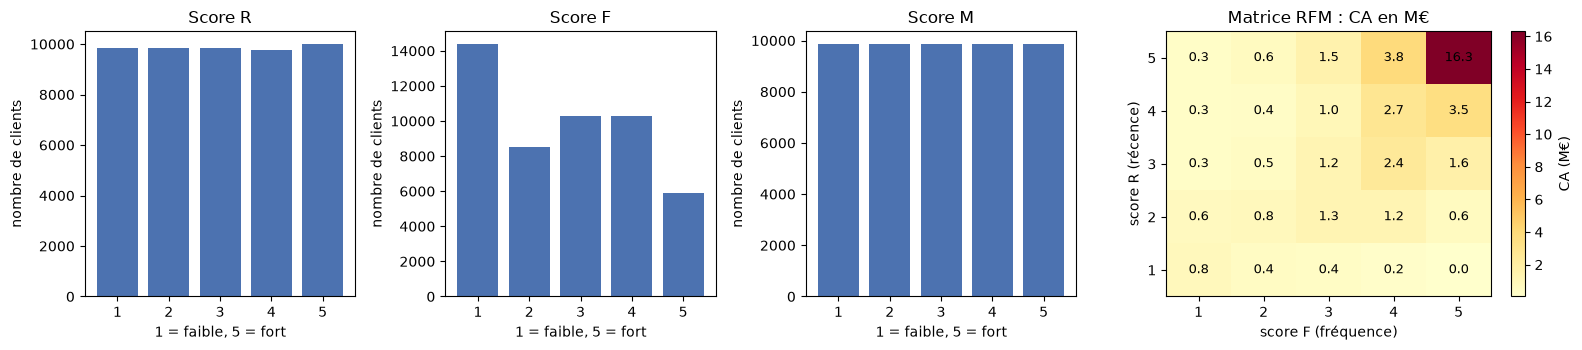

In [15]:
figure, axes = plt.subplots(1, 4, figsize=(16, 3.6),
                            gridspec_kw={"width_ratios": [1, 1, 1, 1.5]})

for axe, score in zip(axes, ["R", "F", "M"]):
    effectifs = rfm[score].value_counts().sort_index()
    axe.bar(effectifs.index, effectifs.values, color="#4c72b0")
    axe.set_title(f"Score {score}")
    axe.set_xlabel("1 = faible, 5 = fort")
    axe.set_ylabel("nombre de clients")
    axe.set_xticks([1, 2, 3, 4, 5])

matrice = rfm.pivot_table(index="R", columns="F", values="montant",
                          aggfunc="sum")
matrice = matrice.sort_index(ascending=False) / 1e6

axe_matrice = axes[3]
image = axe_matrice.imshow(matrice.values, cmap="YlOrRd", aspect="auto")
for ligne in range(5):
    for colonne in range(5):
        valeur = matrice.values[ligne, colonne]
        axe_matrice.text(colonne, ligne, f"{valeur:.1f}",
                         ha="center", va="center", fontsize=9)
axe_matrice.set_xticks(range(5), matrice.columns)
axe_matrice.set_yticks(range(5), matrice.index)
axe_matrice.set_xlabel("score F (fréquence)")
axe_matrice.set_ylabel("score R (récence)")
axe_matrice.set_title("Matrice RFM : CA en M€")
figure.colorbar(image, ax=axe_matrice, label="CA (M€)")

plt.tight_layout()
plt.show()

Les trois premiers graphiques ne servent qu'à vérifier que le scoring s'est bien
passé. R et M sont plats par construction ; seul F montre le déséquilibre assumé
plus haut, avec un score 1 deux fois et demie plus peuplé que le score 5.

La matrice, elle, dit quelque chose. Une seule case écrase tout le reste :
R = 5 et F = 5, les clients à la fois récents et très fréquents, pèsent **16,3 M€
sur 42,6 M€**, soit 38 % du chiffre d'affaires.

La colonne F = 1 est presque vide sur toute sa hauteur, 2,3 M€ cumulés, à peine
5 % du total. Un client qui n'a commandé qu'une fois ne pèse rien même s'il vient
d'acheter : la case R = 5, F = 1 ne fait que 0,3 M€. C'est l'hypothèse 2 du TP1
rendue visible — la valeur se gagne sur la répétition, pas sur le panier.

Un détail va à contre-courant. Dans cette colonne F = 1, le chiffre d'affaires
est plus élevé en bas qu'en haut, 0,8 M€ pour R = 1 contre 0,3 M€ pour R = 5. Ce
n'est pas que les clients anciens dépensent plus : ils sont simplement bien plus
nombreux à n'avoir jamais recommandé, accumulés sur quatre ans.

## 3. Profilage des segments

Un segment dont on ne sait dire que la taille n'est pas caractérisé. « Segment A :
9 311 clients » ne dit rien à personne. Il faut pouvoir décrire qui est dedans
sans avoir à retourner dans les données.

Trois angles ici : d'où viennent-ils, depuis quand sont-ils clients, et combien
mettent-ils par commande. J'ajoute une quatrième colonne, la part de la source A,
parce que le TP1 avait annoncé qu'un segment déséquilibré sur ce point serait un
artefact d'export avant d'être un comportement.

In [16]:
clients_indexes = df_customers.set_index("customer_id")
rfm["pays"] = rfm.index.map(clients_indexes["country"])

source_dominante = ventes.groupby("client_rattache")["source_export"].agg(
    lambda sources: sources.mode()[0]
)
rfm["source"] = rfm.index.map(source_dominante)

profil = rfm.groupby("segment").agg(
    clients=("montant", "size"),
    part_france=("pays", lambda pays: (pays == "France").mean() * 100),
    anciennete_med=("anciennete", "median"),
    panier_med=("panier_moyen", "median"),
    part_source_a=("source", lambda s: (s == "A").mean() * 100),
)
profil = profil.sort_values("anciennete_med")

part_france_base = (rfm["pays"] == "France").mean() * 100
part_source_a_base = (rfm["source"] == "A").mean() * 100

print("moyenne de la base :")
print("  France      : %.1f %%" % part_france_base)
print("  source A    : %.1f %%" % part_source_a_base)
print("  ancienneté  : %.0f jours" % rfm["anciennete"].median())
profil.round(1)

moyenne de la base :
  France      : 91.2 %
  source A    : 14.9 %
  ancienneté  : 561 jours


,clients,part_france,anciennete_med,panier_med,part_source_a
segment,,,,,
Nouveaux prometteurs,5646,88.6,74.0,93.0,12.9
Fidèles,4489,90.6,265.0,89.5,13.7
Occasionnels,7287,90.9,455.0,126.0,18.7
Champions,9311,91.2,575.0,103.1,31.7
En sommeil,6496,91.4,598.0,95.7,9.4
Perdus,10865,91.8,699.0,73.0,2.3
Comptes professionnels,341,92.1,728.0,339.1,85.6
À risque,4893,93.7,817.0,102.9,10.8


**La géographie n'apporte rien.** La part de clients français va de 88,6 % à
93,7 % selon les segments, pour une moyenne de 91,2 %. Aucun segment ne se
distingue. C'était prévisible avec une base française à neuf clients sur dix, et
ça tranche une question : le pays ne servira pas à caractériser les segments,
donc pas non plus à choisir un canal ou une langue.

**L'ancienneté, elle, sépare très bien.** Le classement va de 74 jours pour les
Nouveaux prometteurs à 817 jours pour les clients à risque. Deux lectures
importantes.

Les Nouveaux prometteurs sont réellement nouveaux — 74 jours d'ancienneté
médiane. Ça nuance l'hypothèse 1 du TP1, qui traitait les 14 392 clients à
commande unique comme un bloc. Le RFM les coupe en deux : ceux qui viennent
d'arriver et n'ont pas encore eu le temps de recommander, et ceux qui ont acheté
une fois il y a deux ans et ne reviendront pas. Ce ne sont pas les mêmes gens et
ils n'appellent pas la même action.

Les clients à risque sont les **plus anciens de toute la base**, 817 jours. Ce
sont les vétérans de la marque, ceux qui décrochent après avoir été fidèles
longtemps. C'est ce qui rend leur perte plus coûteuse qu'elle n'en a l'air.

**Le panier médian ne sépare presque pas.** Champions et clients à risque sont à
103 € tous les deux. Un Champion ne dépense pas plus par commande qu'un client en
train de partir, il commande simplement plus souvent. C'est l'hypothèse 2 du TP1
qu'on retrouve segment par segment. Seuls les comptes professionnels décrochent,
à 339 €.

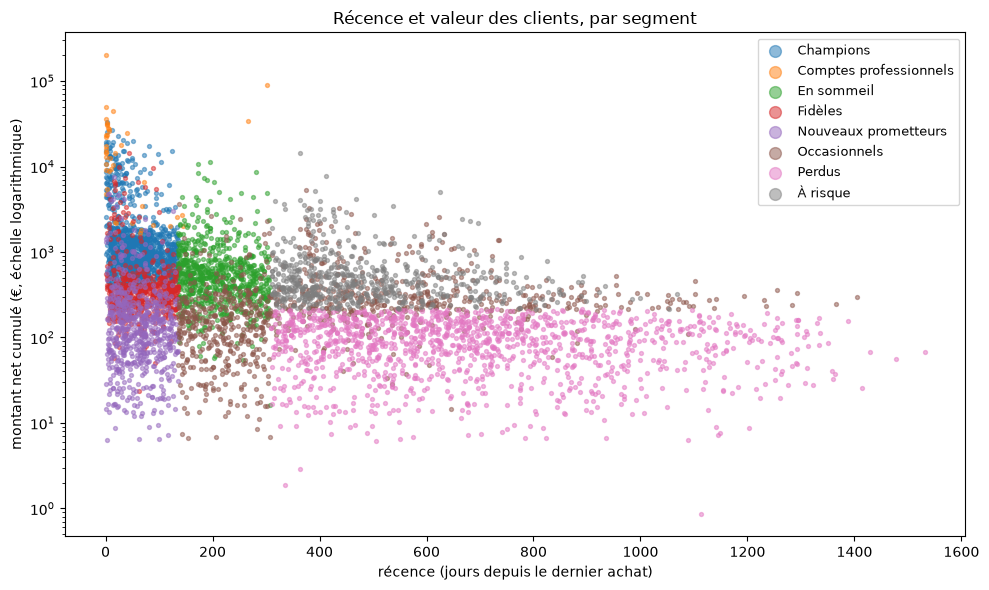

In [17]:
ECHANTILLON = 6000  # lisibilité : 49 328 points formeraient une tache uniforme

clients_positifs = rfm[rfm["montant"] > 0]
echantillon = clients_positifs.sample(ECHANTILLON, random_state=0)

figure, axe = plt.subplots(figsize=(10, 6))

for nom_segment, groupe in echantillon.groupby("segment"):
    axe.scatter(groupe["recence"], groupe["montant"], s=8, alpha=0.5,
                label=nom_segment)

axe.set_yscale("log")
axe.set_xlabel("récence (jours depuis le dernier achat)")
axe.set_ylabel("montant net cumulé (€, échelle logarithmique)")
axe.set_title("Récence et valeur des clients, par segment")
axe.legend(markerscale=3, fontsize=9, loc="upper right")
plt.tight_layout()
plt.show()

Le nuage est coupé en deux verticalement, et la frontière est nette : à gauche
les segments actifs, à droite ceux qui ont décroché. C'est attendu, la récence
est l'un des critères de la grille.

Ce qui l'est moins, c'est l'étalement vertical. À **toutes** les récences, le
montant s'étale sur trois ordres de grandeur. Autrement dit, savoir depuis quand
un client n'a pas acheté ne dit presque rien de ce qu'il a dépensé. Les clients à
risque, tout à droite, montent aussi haut que les Fidèles situés à gauche.

Deux précisions sur le graphique. L'axe des montants est en échelle
logarithmique : sans ça, les comptes professionnels à 400 000 € écraseraient tout
le reste sur une bande d'un pixel. Et je n'ai tracé que 6 000 clients tirés au
hasard, parce qu'avec 49 328 points le nuage devient une tache uniforme où on ne
distingue plus les couleurs.

In [18]:
TRANCHES_RECENCE = [-1, 30, 90, 180, 365, 730, np.inf]
NOMS_TRANCHES = ["0-30 j", "31-90 j", "91-180 j", "181-365 j",
                 "1-2 ans", "plus de 2 ans"]

tranche = pd.cut(rfm["recence"], TRANCHES_RECENCE, labels=NOMS_TRANCHES)

rfm.groupby(tranche, observed=True).agg(
    clients=("montant", "size"),
    montant_median=("montant", "median"),
    montant_p90=("montant", lambda montants: montants.quantile(0.9)),
).round(0)

,clients,montant_median,montant_p90
recence,,,
0-30 j,5442,743.0,7716.0
31-90 j,9510,521.0,1741.0
91-180 j,8141,431.0,1288.0
181-365 j,8711,314.0,966.0
1-2 ans,12312,196.0,709.0
plus de 2 ans,5212,107.0,277.0


Le montant médian tombe de 743 € à 107 € entre les clients du mois et ceux de
plus de deux ans. La relation existe donc bien, mais elle n'est pas droite : elle
chute vite au début puis s'aplatit.

Surtout, la colonne du neuvième décile raconte une autre histoire. Chez les
clients qui n'ont rien acheté depuis un à deux ans, 10 % ont quand même dépensé
plus de 709 €. Ce ne sont pas des petits clients qui sont partis, ce sont de bons
clients qui sont partis.

C'est exactement le piège que le TP signale : traiter la récence comme un
proxy de la valeur ferait sortir des campagnes des gens qui valent cher. Un
client très récent et un client très ancien peuvent tous deux avoir un fort
potentiel, pour des raisons opposées — l'un parce qu'il est engagé, l'autre parce
qu'il a beaucoup donné et qu'on peut espérer le récupérer. C'est ce qui justifie
de croiser les trois dimensions au lieu de trier sur la seule récence.

### Le contrôle promis au TP1, et il est gênant

Le TP1 s'était engagé à vérifier une chose : si un segment se révélait composé
majoritairement d'une seule des deux sources d'export, ce serait un artefact
avant d'être un comportement client. La dernière colonne du tableau de profil
donne la réponse.

La source A représente 14,9 % de la base. Elle pèse **85,6 % des comptes
professionnels**, **31,7 % des Champions**, mais seulement **2,3 % des Perdus**.
Sur-représentée d'un facteur six chez les uns, six fois moins présente chez les
autres.

Ça ne veut pas dire que la segmentation est fausse. Les scores sont calculés sur
des comportements d'achat réels, et un client qui a commandé neuf fois a bien
commandé neuf fois. Mais ça veut dire qu'une partie de ce qui sépare un Champion
d'un Perdu tient à l'export dont il provient, pas seulement à ce qu'il a fait.

Deux explications tiennent, et je ne peux pas trancher entre elles. Soit la
source A contient réellement les meilleurs clients de la marque — un canal de
vente plus qualitatif, par exemple. Soit son historique plus court, qui démarre
en 2024 contre 2022 pour la source B, lui donne mécaniquement de meilleures
récences : quelqu'un dont on ne suit les achats que depuis deux ans a moins de
chances d'apparaître inactif depuis trois ans.

La seconde explication me paraît la plus probable, et elle suffit à faire de ce
point une limite à énoncer devant le CMO plutôt qu'un résultat. La question à
poser avant d'engager du budget est simple : d'où viennent ces deux exports, et
recouvrent-ils le même périmètre commercial ?

## 4. Recommandations et priorisation

Un segment n'est utile que s'il débouche sur une action qui lui est propre. Si
deux segments reçoivent le même email, ils n'en formaient qu'un.

Reste à décider par quoi commencer. Trois critères sont possibles : la valeur
immédiate, le risque de perte, le potentiel de croissance. Ils ne donnent pas le
même classement, et il faut choisir. Je classe par **l'effet attendu d'une
action**, pas par le chiffre d'affaires brut : un segment qui pèse lourd mais va
bien a moins besoin d'attention qu'un segment plus petit qui est en train de
partir.

In [19]:
economie = rfm.groupby("segment").agg(
    clients=("montant", "size"),
    ca=("montant", "sum"),
    recence_med=("recence", "median"),
)
economie["ca_par_client"] = (economie["ca"] / economie["clients"]).round(0)
economie["part_ca"] = (economie["ca"] / economie["ca"].sum() * 100).round(1)

RANGS = {
    "Comptes professionnels": (1, "concentration du risque"),
    "À risque": (2, "valeur en train de sortir"),
    "Champions": (3, "valeur immédiate à protéger"),
    "En sommeil": (4, "risque précoce, peu cher à traiter"),
    "Nouveaux prometteurs": (5, "potentiel de croissance"),
    "Fidèles": (6, "potentiel de montée en valeur"),
    "Occasionnels": (7, "faible valeur, faible engagement"),
    "Perdus": (8, "coût à limiter"),
}

economie["rang"] = [RANGS[nom][0] for nom in economie.index]
economie["critere"] = [RANGS[nom][1] for nom in economie.index]
economie = economie.sort_values("rang")

economie[["rang", "critere", "clients", "part_ca", "ca_par_client",
          "recence_med"]]

,rang,critere,clients,part_ca,ca_par_client,recence_med
segment,,,,,,
Comptes professionnels,1,concentration du risque,341,17.8,22217.0,9.0
À risque,2,valeur en train de sortir,4893,8.2,717.0,454.0
Champions,3,valeur immédiate à protéger,9311,44.4,2030.0,53.0
En sommeil,4,"risque précoce, peu cher à traiter",6496,11.9,778.0,201.0
Nouveaux prometteurs,5,potentiel de croissance,5646,3.4,257.0,59.0
Fidèles,6,potentiel de montée en valeur,4489,6.2,588.0,61.0
Occasionnels,7,"faible valeur, faible engagement",7287,5.8,336.0,354.0
Perdus,8,coût à limiter,10865,2.4,94.0,650.0


Le chiffre d'affaires par client va de **22 217 € pour un compte professionnel à
94 € pour un client perdu**, soit un facteur 236. C'est ce rapport qui justifie
tout le reste : envoyer le même message aux deux revient à dépenser autant pour
l'un que pour l'autre.

Deux points d'arbitrage à assumer.

**Pourquoi les comptes professionnels en premier alors qu'ils ne pèsent que 18 %
du chiffre d'affaires ?** Parce qu'ils sont 341. Il suffit de 46 d'entre eux pour
peser autant que les 10 865 clients perdus réunis. Une concentration pareille est
un risque en soi : le départ d'une poignée de comptes se voit immédiatement dans
le chiffre d'affaires, alors qu'aucune action marketing de masse ne peut le
compenser.

**Pourquoi les Champions seulement en troisième alors qu'ils font 44 % du chiffre
d'affaires ?** Parce qu'ils vont bien — 53 jours de récence médiane. L'action
qu'on mènera sur eux protège une position, elle ne la crée pas. Les clients à
risque, eux, représentent 3,5 M€ d'historique en train de sortir, et une relance
peut encore en récupérer une partie.

C'est un choix discutable et je le dis comme tel : un CMO qui classerait par
valeur brute mettrait les Champions en tête. L'argument qui me fait trancher
autrement est que 44 % du chiffre d'affaires ne sont pas menacés aujourd'hui,
alors que les 8 % des clients à risque le sont.

### Rangs 1 à 3 — la valeur en jeu

**1. Comptes professionnels** — 341 clients, 18 % du CA

*Qui sont-ils.* 34 commandes en médiane, panier de 339 €, 728 jours d'ancienneté,
9 jours de récence. Ils achètent en continu et en gros. Ce ne sont pas des
particuliers : leur comportement n'a aucun équivalent dans le reste de la base.

*Potentiel.* 22 217 € par client et par an. Le plus élevé de tous les segments,
de très loin.

*Risque.* La concentration. 46 comptes pèsent autant que les 10 865 clients
perdus. Un départ non détecté coûte immédiatement.

*Action.* Les **sortir des campagnes de masse** et leur affecter un contact
commercial nommé, avec conditions tarifaires négociées et alerte automatique en
cas de baisse de commandes.

> Pour le segment **Comptes professionnels**, caractérisé par 34 commandes
> médianes et un panier de 339 €, priorisé en position **1** parce que la valeur
> y est concentrée sur 341 clients, on propose un suivi commercial individuel
> hors dispositif marketing.

---

**2. À risque** — 4 893 clients, 8 % du CA

*Qui sont-ils.* Les plus anciens de la base, 817 jours. 4 commandes, 437 €
dépensés, mais plus rien depuis 454 jours. Des vétérans qui décrochent.

*Potentiel.* 717 € par client déjà réalisés, donc un historique qui prouve qu'ils
savent acheter. C'est la valeur la plus facile à récupérer, parce qu'il n'y a
rien à leur apprendre sur la marque.

*Risque.* Ils sont déjà partis dans les faits. Passé un certain délai, une
relance ne coûte plus seulement de l'argent, elle réactive une mauvaise
expérience.

*Action.* Une **campagne de reconquête à durée limitée**, avec une offre
significative et un message qui reconnaît l'absence. Si elle échoue, on les
bascule en Perdus plutôt que de la répéter.

> Pour le segment **À risque**, caractérisé par 817 jours d'ancienneté et
> 454 jours sans achat malgré 4 commandes passées, priorisé en position **2**
> parce que la valeur en sort en ce moment, on propose une campagne de
> reconquête unique avec bascule automatique en cas d'échec.

---

**3. Champions** — 9 311 clients, 44 % du CA

*Qui sont-ils.* 9 commandes, 1 006 € dépensés, 53 jours de récence. Le cœur
économique de la marque.

*Potentiel.* 2 030 € par client. Leur panier médian est pourtant de 103 €, le
même que les clients à risque : leur valeur vient du nombre de commandes, pas du
montant de chacune. Il n'y a donc rien à gagner à leur vendre plus cher.

*Risque.* Faible à court terme, mais l'exposition est énorme : perdre 10 % de ce
segment coûterait 1,9 M€.

*Action.* Un **programme de fidélité** qui récompense la fréquence et non le
montant — accès anticipé aux nouveautés, avantages liés au nombre de commandes.
Surtout, une surveillance de leur récence pour les attraper avant qu'ils ne
glissent vers « En sommeil ».

> Pour le segment **Champions**, caractérisé par 9 commandes et 53 jours de
> récence, priorisé en position **3** parce qu'il porte 44 % du chiffre
> d'affaires sans être menacé aujourd'hui, on propose un programme de fidélité
> indexé sur la fréquence et une alerte de récence.

### Rangs 4 à 6 — le potentiel

**4. En sommeil** — 6 496 clients, 12 % du CA

*Qui sont-ils.* 5 commandes, 518 € dépensés, mais 201 jours de récence. Ils n'ont
pas coupé le lien, ils ralentissent.

*Potentiel.* 778 € par client, davantage que les clients à risque. Et surtout un
coût de traitement bien inférieur : les ramener après six mois est plus facile
qu'après quinze.

*Risque.* Sans action, ils deviennent le segment « À risque » de l'an prochain.
C'est le segment que la grille du cours ne voyait pas, noyé dans les « Clients
moyens ».

*Action.* Une **relance douce et automatique**, déclenchée à 180 jours sans
commande — rappel produit, réassort de ce qu'ils ont déjà acheté. Pas d'offre
agressive, ils n'en ont pas besoin.

> Pour le segment **En sommeil**, caractérisé par 5 commandes et 201 jours sans
> achat, priorisé en position **4** parce qu'une relance y coûte moins cher
> qu'une reconquête, on propose un déclencheur automatique de réassort à
> 180 jours.

---

**5. Nouveaux prometteurs** — 5 646 clients, 3 % du CA

*Qui sont-ils.* 74 jours d'ancienneté, une seule commande à 130 €. Ce sont de
vrais nouveaux clients, pas des clients perdus : le profilage de la partie 3 l'a
confirmé.

*Potentiel.* Le plus fort en relatif. Leur panier de 93 € est comparable à celui
des Champions. Ce qui leur manque n'est pas le budget, c'est une raison de
revenir.

*Risque.* Sans deuxième commande, ils rejoignent les Perdus. C'est le moment où
tout se joue.

*Action.* Une **séquence de deuxième commande** dans les 60 jours suivant la
première : conseil d'usage, produit complémentaire, avantage sur le second achat.
Distincte du programme de fidélité, qui ne leur parle pas encore.

> Pour le segment **Nouveaux prometteurs**, caractérisé par 74 jours
> d'ancienneté et une commande unique à 130 €, priorisé en position **5** parce
> que le potentiel y est maximal, on propose une séquence de deuxième commande
> déclenchée à 60 jours.

---

**6. Fidèles** — 4 489 clients, 6 % du CA

*Qui sont-ils.* 61 jours de récence, 4 commandes, 265 jours d'ancienneté. Des
clients réguliers et récents, mais plus jeunes que les Champions.

*Potentiel.* 588 € par client contre 2 030 € pour un Champion. L'écart tient
surtout à l'ancienneté : ce sont des Champions en formation.

*Risque.* Faible. Le vrai coût serait de ne rien faire et de les laisser
plafonner.

*Action.* Du **cross-selling par catégorie**. Le TP1 avait montré que le soin
visage fait un tiers du chiffre d'affaires : leur proposer les catégories qu'ils
n'ont pas encore essayées est le moyen le plus direct d'augmenter leur fréquence.

> Pour le segment **Fidèles**, caractérisé par 4 commandes en 265 jours,
> priorisé en position **6** parce qu'ils peuvent devenir des Champions, on
> propose des recommandations croisées sur les catégories non achetées.

### Rangs 7 et 8 — limiter le coût

**7. Occasionnels** — 7 287 clients, 6 % du CA

*Qui sont-ils.* 2 commandes, 354 jours de récence, 224 € dépensés. Le segment le
plus flou : ni assez actifs pour être fidèles, ni assez éteints pour être perdus.

*Potentiel.* 336 € par client. Leur panier de 126 € est pourtant le deuxième plus
élevé après les comptes professionnels, ce qui reste inexpliqué et mériterait
d'être creusé.

*Risque.* Le principal risque est de dépenser pour eux sans retour, vu leur
nombre.

*Action.* Les laisser dans les **envois génériques à coût marginal nul** —
newsletter, annonces de nouveautés — sans budget dédié. Et tester une offre sur
un échantillon avant d'envisager mieux.

> Pour le segment **Occasionnels**, caractérisé par 2 commandes et 354 jours de
> récence, priorisé en position **7** parce que la valeur unitaire y est faible,
> on propose le maintien en newsletter sans budget dédié.

---

**8. Perdus** — 10 865 clients, 2 % du CA

*Qui sont-ils.* Le plus gros segment en nombre, 22 % de la base. Une commande,
89 € dépensés, 650 jours de récence.

*Potentiel.* 94 € par client. Le plus faible de tous, 236 fois moins qu'un compte
professionnel.

*Risque.* Celui de dépenser pour eux. À budget égal, chaque euro dépensé ici est
un euro non dépensé sur un segment qui rapporte.

*Action.* Les **sortir des campagnes payantes**. C'est contre-intuitif et c'est
la bonne décision : les reconquérir coûterait plus que ce qu'ils rapporteraient.
On garde au mieux un envoi occasionnel à coût nul, et on nettoie la base pour
arrêter de payer un routeur pour des adresses inactives.

> Pour le segment **Perdus**, caractérisé par une commande unique à 89 € et
> 650 jours de récence, priorisé en position **8** parce que le coût de
> reconquête dépasserait le gain, on propose la sortie de tout dispositif
> payant.

### Le budget suit-il vraiment cet ordre ?

Une priorisation qui ne change pas l'allocation des moyens n'est qu'un tableau.
Je pose donc un budget annuel de 200 000 € — chiffre rond, à ajuster par le CMO —
et je le répartis selon les rangs, puis je vérifie que deux segments de rangs
éloignés ne reçoivent pas le même traitement.

In [20]:
BUDGET_ANNUEL = 200_000  # hypothèse de travail, à valider par le CMO

REPARTITION = {
    "Comptes professionnels": 20,
    "À risque": 20,
    "Champions": 25,
    "En sommeil": 15,
    "Nouveaux prometteurs": 10,
    "Fidèles": 7,
    "Occasionnels": 3,
    "Perdus": 0,
}

budget = economie[["rang", "clients", "ca", "ca_par_client"]].copy()
budget["part_budget_pct"] = [REPARTITION[nom] for nom in budget.index]
budget["budget_eur"] = BUDGET_ANNUEL * budget["part_budget_pct"] / 100
par_client = budget["budget_eur"] / budget["clients"]
sur_ca = budget["budget_eur"] / budget["ca"] * 100
budget["budget_par_client"] = par_client.round(2)
budget["budget_sur_ca_pct"] = sur_ca.round(2)

budget[["rang", "part_budget_pct", "budget_eur", "budget_par_client",
        "budget_sur_ca_pct"]]

,rang,part_budget_pct,budget_eur,budget_par_client,budget_sur_ca_pct
segment,,,,,
Comptes professionnels,1,20,40000.0,117.30,0.53
À risque,2,20,40000.0,8.17,1.14
Champions,3,25,50000.0,5.37,0.26
En sommeil,4,15,30000.0,4.62,0.59
Nouveaux prometteurs,5,10,20000.0,3.54,1.38
Fidèles,6,7,14000.0,3.12,0.53
Occasionnels,7,3,6000.0,0.82,0.24
Perdus,8,0,0.0,0.00,0.00


La vérification passe. Le budget par client va de **117 € pour un compte
professionnel à 0 € pour un client perdu**, et le rang 1 reçoit 25 fois plus par
client que le rang 4. Deux segments de rangs éloignés ne recevraient donc pas le
même traitement, ce qui était la condition à remplir.

La dernière colonne est celle qui compte pour le CMO : le budget rapporté au
chiffre d'affaires du segment. On dépense 0,53 % sur les comptes professionnels
contre 0,26 % sur les Champions, alors que ces derniers pèsent deux fois et demie
plus. C'est délibéré : un compte-clé se travaille par un contact humain, ce qui
coûte plus cher qu'un email.

Les deux taux les plus élevés sont ailleurs, et ils disent la même chose. Les
Nouveaux prometteurs reçoivent 1,38 % de leur chiffre d'affaires et les clients à
risque 1,14 %. Ce sont les deux segments où l'on investit au-delà de ce qu'ils
rapportent aujourd'hui, pour des raisons opposées : chez les uns on paie une
activation, chez les autres une tentative de récupération. Dans les deux cas la
dépense n'est justifiée qu'une fois, et il faudra mesurer si elle a produit
quelque chose avant de la reconduire.

Une réserve d'honnêteté sur ce tableau. Les 200 000 € sont une hypothèse de
travail, pas un budget réel, et la répartition en pourcentages vient de mon
classement, pas d'un modèle de retour sur investissement. Ce qu'il démontre,
c'est que la priorisation est traduisible en décisions concrètes — pas qu'elle
est optimale.

## 5. Faut-il découper les segments plus finement ?

Les huit segments répondent à la question du CMO, mais chacun contient encore des
clients très différents. Un Champion à 800 € et un Champion à 5 000 € reçoivent
aujourd'hui le même traitement. La question est donc de savoir s'il vaut le coup
de couper certains segments en deux.

Le réflexe serait de regarder si les segments sont hétérogènes et de couper ceux
qui le sont. Testons-le avant d'y croire.

In [21]:
SEUIL_COUPE = 0.75  # on compare le quart supérieur au reste

comparaisons = []
for nom_segment, groupe in rfm.groupby("segment"):
    limite = groupe["montant"].quantile(SEUIL_COUPE)
    quart_haut = groupe[groupe["montant"] >= limite]
    reste = groupe[groupe["montant"] < limite]
    comparaisons.append({
        "segment": nom_segment,
        "clients": len(groupe),
        "montant_quart_haut": round(quart_haut["montant"].median()),
        "montant_reste": round(reste["montant"].median()),
        "ecart": round(quart_haut["montant"].median()
                       / reste["montant"].median(), 1),
    })

test_de_coupe = pd.DataFrame(comparaisons).set_index("segment")
test_de_coupe.sort_values("ecart", ascending=False)

,clients,montant_quart_haut,montant_reste,ecart
segment,,,,
Comptes professionnels,341,36878,9477,3.9
Champions,9311,3066,832,3.7
Nouveaux prometteurs,5646,340,98,3.5
Occasionnels,7287,501,182,2.8
En sommeil,6496,1134,417,2.7
À risque,4893,1017,372,2.7
Perdus,10865,170,69,2.5
Fidèles,4489,658,290,2.3


Voilà pourquoi il fallait tester. **L'écart va de 2,3 à 3,9, mais il est
significatif partout.** Aucun segment ne ressort comme « celui qu'il faut
couper » : découper un groupe au troisième quartile crée toujours un écart de
valeur, par construction. Le critère statistique ne décide donc rien, et s'y
fier reviendrait à sous-segmenter les huit sans raison.

Ce qui doit décider, c'est l'action. Je retiens trois conditions cumulatives.

**La taille.** Chaque moitié doit rester ciblable. En dessous d'un millier de
clients, une campagne dédiée n'a plus de sens — sauf en B2B, où le contact est
nominatif et où quelques dizaines de comptes suffisent.

**L'action.** Les deux moitiés doivent appeler deux actions *différentes*, pas
deux intensités de la même. Envoyer le même email avec une remise de 10 % d'un
côté et 20 % de l'autre ne justifie pas de créer un segment.

**La priorité.** Le segment doit être assez haut dans le classement de la partie
4. Passer du temps à affiner un segment de rang 7 contredirait la priorisation
qu'on vient d'établir.

Quatre segments passent les trois conditions.

In [22]:
# Pour chaque segment retenu : sur quoi on coupe, et comment on nomme les deux
# moitiés. Le montant sert de critère partout sauf pour les nouveaux clients,
# qui n'ont qu'une commande — c'est leur panier qui porte l'information.
SOUS_SEGMENTS = {
    "Comptes professionnels": ("montant", "Grands comptes", "Pros standards"),
    "À risque": ("montant", "À risque forte valeur",
                 "À risque valeur modérée"),
    "Champions": ("montant", "Champions élite", "Champions réguliers"),
    "Nouveaux prometteurs": ("panier_moyen", "Nouveaux à fort panier",
                             "Nouveaux en découverte"),
}

rfm["sous_segment"] = rfm["segment"]

for segment, (critere, nom_haut, nom_bas) in SOUS_SEGMENTS.items():
    dans_le_segment = rfm["segment"] == segment
    limite = rfm.loc[dans_le_segment, critere].quantile(SEUIL_COUPE)
    quart_haut = dans_le_segment & (rfm[critere] >= limite)
    rfm.loc[dans_le_segment, "sous_segment"] = nom_bas
    rfm.loc[quart_haut, "sous_segment"] = nom_haut

detail = rfm[rfm["segment"].isin(SOUS_SEGMENTS)].groupby("sous_segment").agg(
    clients=("montant", "size"),
    ca=("montant", "sum"),
    frequence_med=("frequence", "median"),
    montant_med=("montant", "median"),
    panier_med=("panier_moyen", "median"),
)
detail["part_ca_total"] = (detail["ca"] / rfm["montant"].sum() * 100).round(1)
detail["ca_Meur"] = (detail["ca"] / 1e6).round(2)
detail["montant_med"] = detail["montant_med"].round(0)
detail["panier_med"] = detail["panier_med"].round(0)

COLONNES_DETAIL = ["clients", "ca_Meur", "part_ca_total", "frequence_med",
                   "montant_med", "panier_med"]
detail[COLONNES_DETAIL].sort_values("ca_Meur", ascending=False)

,clients,ca_Meur,part_ca_total,frequence_med,montant_med,panier_med
sous_segment,,,,,,
Champions élite,2328,12.78,30.0,14.0,3066.0,334.0
Champions réguliers,6983,6.12,14.4,9.0,832.0,95.0
Grands comptes,86,4.93,11.6,48.5,36878.0,783.0
Pros standards,255,2.64,6.2,30.0,9477.0,231.0
À risque forte valeur,1224,2.07,4.9,7.0,1017.0,141.0
À risque valeur modérée,3669,1.43,3.4,4.0,372.0,95.0
Nouveaux à fort panier,1412,0.99,2.3,1.0,340.0,235.0
Nouveaux en découverte,4234,0.46,1.1,1.0,98.0,72.0


Les quatre coupes séparent bien plus que la valeur, et c'est ce qui les justifie.

**Comptes professionnels.** 86 grands comptes contre 255 pros standards, avec un
panier de 783 € face à 231 €. Le nombre change tout : 86 comptes se suivent
nommément, un commercial peut les connaître un par un. 255, non. La coupe fait
donc passer d'une intention — « traiter les pros à part » — à deux dispositifs
concrets, un suivi individuel et une offre B2B standardisée.

**Champions.** 2 328 élites contre 6 983 réguliers, mais surtout un panier de
334 € contre 95 €. Les Champions réguliers achètent au panier moyen de la base et
souvent ; les élites achètent souvent *et* beaucoup à chaque fois. Ce sont deux
comportements, pas deux niveaux du même. À eux seuls, les 2 328 élites portent
près d'un tiers du chiffre d'affaires total de la marque.

**À risque.** 1 224 clients à 1 017 € d'historique contre 3 669 à 372 €. Ici la
coupe sert à calibrer la dépense : une offre de reconquête généreuse se finance
sur un client qui a dépensé mille euros, pas sur un qui en a dépensé trois cents.
Sans cette distinction, on choisit forcément mal — soit on est trop timide avec
les premiers, soit on dépense trop pour les seconds.

**Nouveaux prometteurs.** Un premier achat à 340 € n'a pas le même sens qu'un
premier achat à 98 €. Les deux groupes ont la même ancienneté et la même récence,
donc le panier est la seule information disponible sur eux — et c'est le seul
signal d'intention qu'on ait à ce stade.

### Les actions, affinées

Les fiches de la partie 4 restent valables. Chaque sous-segment reçoit une
variante, pas une nouvelle stratégie.

| Sous-segment | Clients | Variante d'action |
|---|---|---|
| Grands comptes | 86 | Commercial nommé, revue trimestrielle, conditions négociées |
| Pros standards | 255 | Offre B2B en libre-service, tarif dégressif automatique |
| Champions élite | 2 328 | Exclusivités et accès anticipé ; ne rien vendre de plus, protéger |
| Champions réguliers | 6 983 | Fidélité indexée sur la fréquence, pas sur le montant |
| À risque forte valeur | 1 224 | Reconquête personnalisée, offre significative, contact unique |
| À risque valeur modérée | 3 669 | Relance automatisée à faible coût, sans offre |
| Nouveaux à fort panier | 1 412 | Séquence premium : conseil personnalisé, gamme complète |
| Nouveaux en découverte | 4 234 | Séquence découverte : échantillon, produit d'appel |

La ligne la plus contre-intuitive est celle des Champions élite. Ce sont les
meilleurs clients de la marque et la tentation serait de leur vendre davantage.
Le TP1 avait pourtant montré que la valeur ne vient pas du panier mais de la
répétition, et la partie 3 l'a confirmé segment par segment. Sur ce groupe
précis, l'objectif n'est pas de faire monter le panier, c'est de ne pas les
perdre.

### Les quatre segments que je ne coupe pas

Ne pas couper est aussi une décision, et elle se justifie.

**En sommeil** (rang 4). L'écart de valeur est de 2,7, ce qui passerait le test
statistique. Mais les deux moitiés ont la même récence, 188 et 206 jours, et
appellent le même déclencheur de relance à 180 jours. C'est une différence
d'intensité, pas de nature.

**Fidèles** (rang 6). L'écart le plus faible des huit. Le cross-selling par
catégorie s'applique de la même façon aux deux moitiés.

**Occasionnels** (rang 7). Celui-là me gêne, parce que l'écart de panier y est
fort — 386 € contre 102 €. Il y a probablement quelque chose à comprendre dans ce
segment. Mais il est au rang 7 : y consacrer du temps contredirait la
priorisation qu'on vient de poser. Je le note comme une piste pour plus tard
plutôt que de me contredire.

**Perdus** (rang 8). Le segment le plus homogène de tous, et de toute façon les
deux moitiés sortent des campagnes payantes de la même manière. Couper ne
changerait rien.

### Une piste à vérifier avant le Jour 3

Les Champions élite ont un panier médian de 334 €. Les comptes professionnels, de
339 €. C'est presque identique, alors que ce sont censés être deux populations
différentes.

Deux lectures possibles. Soit une partie des Champions élite sont en réalité des
comptes professionnels que le seuil `profil_atypique` du TP1 n'a pas attrapés —
ce seuil était fixé sur le nombre de commandes, pas sur le panier, et un
revendeur qui commande peu mais gros passerait entre les mailles. Soit il existe
vraiment des particuliers à très gros panier, ce qui serait une information
intéressante en soi.

Je ne tranche pas ici, je n'ai pas de quoi. Mais si c'est la première explication,
le segment Champions est un peu surestimé et les comptes professionnels
sous-estimés. À creuser avec les données de campagne du Jour 3, qui diront si ces
clients réagissent aux emails grand public — un revendeur, non.